In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import accuracy_score  
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm as lgb
import warnings, random
from datetime import datetime, timedelta
warnings.filterwarnings("ignore")

seed = 1
random.seed(seed)
np.random.seed(seed)

df = pd.read_csv('SE5.csv')
forward_test_df = pd.read_csv('SE5-2.csv')
df['Time'] = pd.to_datetime(df['Time'])
forward_test_df['Time'] = pd.to_datetime(forward_test_df['Time'])
df = df.sort_values(by='Time', ascending=True)
forward_test_df = forward_test_df.sort_values(by='Time', ascending=True)
train_val_df = df[df["Time"] < "2024-01-01"]
test_df = df[df["Time"] >= "2024-01-01"]
regime_intervals = pd.read_csv('Regime_intervals_cleaned.csv')
regime_intervals['Start'] = pd.to_datetime(regime_intervals['Start'])
regime_intervals['End'] = pd.to_datetime(regime_intervals['End'])
macro_level_features = np.loadtxt('macro_level_features.txt', dtype='O')

print(f"Train/Validation data shape: {train_val_df.shape}")
print(f"Test data shape: {test_df.shape}")
print(f"Forward Test data shape: {forward_test_df.shape}")

Train/Validation data shape: (40884, 717)
Test data shape: (2313, 717)
Forward Test data shape: (1182, 717)


In [ ]:
# Labeling data based on regime intervals file 

# train_val_df['State'] = pd.NA
# for index, row in train_val_df.iterrows():
#     time_point = row['Time']
#     assigned_state = pd.NA
#     for _, regime_row in regime_intervals.iterrows():
#         start_date = regime_row['Start']
#         end_date = regime_row['End'] + timedelta(days=7)  # Add 7 days to the End date
#         if start_date <= time_point <= end_date:
#             assigned_state = regime_row['State']
#             break  # Found a matching regime, no need to check further
#     train_val_df.at[index, 'State'] = assigned_state

# test_df['State'] = pd.NA
# for index, row in test_df.iterrows():
#     time_point = row['Time']
#     assigned_state = pd.NA
#     for _, regime_row in regime_intervals.iterrows():
#         start_date = regime_row['Start']
#         end_date = regime_row['End'] + timedelta(days=7)  # Add 7 days to the End date
#         if start_date <= time_point <= end_date:
#             assigned_state = regime_row['State']
#             break  # Found a matching regime, no need to check further
#     test_df.at[index, 'State'] = assigned_state

# forward_test_df['State'] = pd.NA
# for index, row in forward_test_df.iterrows():
#     time_point = row['Time']
#     assigned_state = pd.NA
#     for _, regime_row in regime_intervals.iterrows():
#         start_date = regime_row['Start']
#         end_date = regime_row['End'] + timedelta(days=7)  # Add 7 days to the End date
#         if start_date <= time_point <= end_date:
#             assigned_state = regime_row['State']
#             break  # Found a matching regime, no need to check further
#     forward_test_df.at[index, 'State'] = assigned_state

# train_val_df[['Time','State']].to_csv('train_val_df_Time-State_for_sanity_check.csv', index=False)
# test_df[['Time','State']].to_csv('test_df_Time-State_for_sanity_check.csv', index=False)
# forward_test_df[['Time','State']].to_csv('forward_test_df_Time-State_for_sanity_check.csv', index=False)

In [10]:
train_val_df['Regime'] = pd.read_csv('regime_intervals/train_val_df_Time-State.csv')['State'].values
test_df['Regime'] = pd.read_csv('regime_intervals/test_df_Time-State.csv')['State'].values
forward_test_df['Regime'] = pd.read_csv('regime_intervals/forward_test_df_Time-State.csv')['State'].values

In [ ]:
train_val_df['Regime'].value_counts().sort_index(), test_df['Regime'].value_counts().sort_index() , forward_test_df['Regime'].value_counts().sort_index()

(Regime
 0    12672
 1    16405
 2     3922
 3     7885
 Name: count, dtype: int64,
 Regime
 0    1511
 1     530
 3     272
 Name: count, dtype: int64,
 Regime
 1    767
 3    415
 Name: count, dtype: int64)

<Axes: title={'center': 'Training / Validation Data [2008-2023]'}, ylabel='count'>

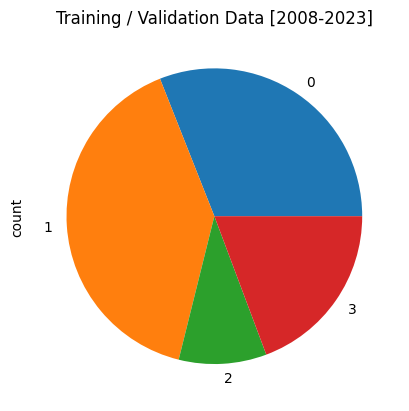

In [27]:
train_val_df['Regime'].value_counts().sort_index().plot(kind='pie', title='Training / Validation Data [2008-2023]')

<Axes: title={'center': 'Test 2024'}, ylabel='count'>

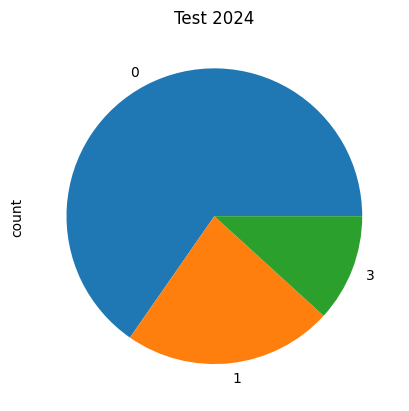

In [29]:
test_df['Regime'].value_counts().sort_index().plot(kind='pie', title='Test 2024')

<Axes: title={'center': 'Test 2025'}, ylabel='count'>

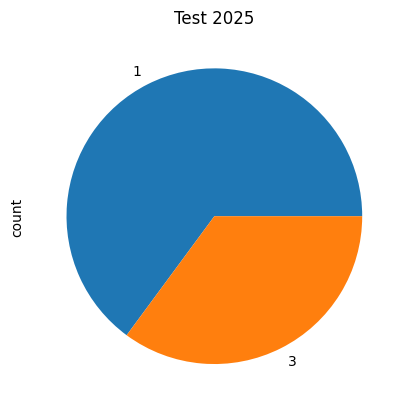

In [30]:
forward_test_df['Regime'].value_counts().sort_index().plot(kind='pie', title='Test 2025')

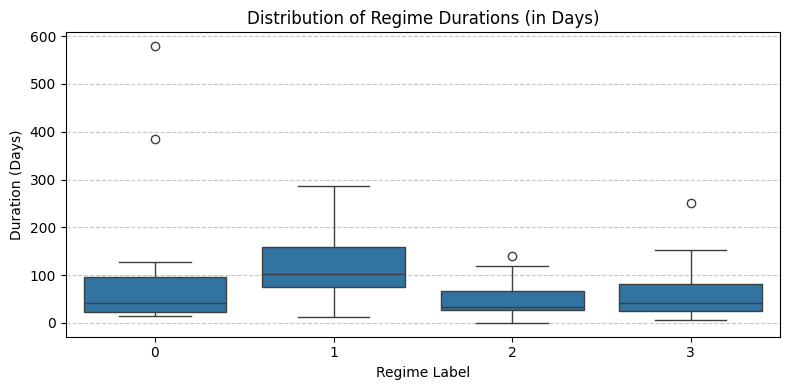

In [19]:
train_val_df['Regime_Shift'] = (train_val_df['Regime'] != train_val_df['Regime'].shift(1)).cumsum()
regime_durations = train_val_df.groupby(['Regime_Shift', 'Regime'])['Time'].apply(lambda x: (x.max() - x.min()).days).reset_index(name='Duration_Days')

plt.figure(figsize=(8, 4))
sns.boxplot(x='Regime', y='Duration_Days', data=regime_durations)
plt.title('Distribution of Regime Durations (in Days)')
plt.xlabel('Regime Label')
plt.ylabel('Duration (Days)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [20]:
# Extracting training data
train_val_df.drop(columns=['Regime_Shift'], inplace=True)
train_val_df[train_val_df['Regime']==0].to_csv('subsets_intervals/subset_r0.csv', index=False)
train_val_df[train_val_df['Regime']==1].to_csv('subsets_intervals/subset_r1.csv', index=False)
train_val_df[train_val_df['Regime']==2].to_csv('subsets_intervals/subset_r2.csv', index=False)
train_val_df[train_val_df['Regime']==3].to_csv('subsets_intervals/subset_r3.csv', index=False)

In [21]:
# exporting as csv
test_df[test_df['Regime']==0].to_csv('subsets_intervals/test_r0.csv', index=False)
test_df[test_df['Regime']==1].to_csv('subsets_intervals/test_r1.csv', index=False)
test_df[test_df['Regime']==2].to_csv('subsets_intervals/test_r2.csv', index=False)
test_df[test_df['Regime']==3].to_csv('subsets_intervals/test_r3.csv', index=False)

In [22]:
# exporting as csv
forward_test_df[forward_test_df['Regime']==0].to_csv('subsets_intervals/forward_test_r0.csv', index=False)
forward_test_df[forward_test_df['Regime']==1].to_csv('subsets_intervals/forward_test_r1.csv', index=False)
forward_test_df[forward_test_df['Regime']==2].to_csv('subsets_intervals/forward_test_r2.csv', index=False)
forward_test_df[forward_test_df['Regime']==3].to_csv('subsets_intervals/forward_test_r3.csv', index=False)